# Experiment 6: GloVe Word Embeddings and Statistical Language Modelling

**Course:** Natural Language Processing  
**Experiment objectives**

1. Implement the **GloVe (Global Vectors for Word Representation)** algorithm from scratch using a text corpus and identify words most similar to **“king”**.
2. Generate word embeddings using a **pretrained GloVe model through Gensim** and find words most similar to **“king”**.
3. Implement a **statistical N-gram language model from scratch** to predict the next word from the preceding context.

## 1. Setup and Imports

In [1]:
import sys
import subprocess
import importlib.util

required = {
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "gensim": "gensim"
}

for module, package in required.items():
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])

import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from sklearn.decomposition import PCA

np.random.seed(42)
print("Environment ready.")

Environment ready.


## 2. Load the GloVe Corpus

In [2]:
from pathlib import Path

corpus_path = Path("glove_corpus.txt")

embedded_corpus = [
    "The king rules the kingdom.",
    "The queen rules the kingdom.",
    "The king is a powerful man.",
    "The queen is a wise woman.",
    "The man is strong and brave.",
    "The woman is intelligent and kind.",
    "The king and queen rule together.",
    "The man and woman live in the kingdom.",
    "The prince is the son of the king.",
    "The princess is the daughter of the queen.",
    "The king lives in a royal palace.",
    "The queen lives in a royal palace.",
    "A doctor treats a patient.",
    "A teacher teaches students in a school.",
    "Students read books and learn new things.",
    "A computer processes data and information.",
    "A computer scientist develops software.",
    "The scientist conducts research in a laboratory.",
    "The cat drinks milk.",
    "The dog eats food.",
    "The cat and dog live in a house.",
    "The sun gives light and heat.",
    "The moon shines at night.",
    "The earth revolves around the sun."
]

if corpus_path.exists():
    raw_lines = corpus_path.read_text(encoding="utf-8").splitlines()
    corpus = [line.strip() for line in raw_lines if line.strip()]
    print(f"Loaded {len(corpus)} lines from {corpus_path.resolve()}")
else:
    corpus = embedded_corpus.copy()
    print("glove_corpus.txt not found; using the supplied corpus embedded in this notebook.")

print("\nSample sentences:")
for sentence in corpus[:5]:
    print("-", sentence)

glove_corpus.txt not found; using the supplied corpus embedded in this notebook.

Sample sentences:
- The king rules the kingdom.
- The queen rules the kingdom.
- The king is a powerful man.
- The queen is a wise woman.
- The man is strong and brave.


## 3. Text Preprocessing

GloVe is trained from word co-occurrence counts. We lowercase the text, extract word tokens, and retain sentence boundaries so that co-occurrences are counted within a sentence.

In [3]:
def tokenize(text):
    return re.findall(r"[a-z]+", text.lower())

tokenized_corpus = [tokenize(sentence) for sentence in corpus]
print("Number of sentences:", len(tokenized_corpus))
print("First tokenized sentence:", tokenized_corpus[0])

vocabulary = sorted({word for sentence in tokenized_corpus for word in sentence})
word_to_id = {word: idx for idx, word in enumerate(vocabulary)}
id_to_word = {idx: word for word, idx in word_to_id.items()}

print("Vocabulary size:", len(vocabulary))
print("Vocabulary:", vocabulary)

Number of sentences: 24
First tokenized sentence: ['the', 'king', 'rules', 'the', 'kingdom']
Vocabulary size: 68
Vocabulary: ['a', 'and', 'around', 'at', 'books', 'brave', 'cat', 'computer', 'conducts', 'data', 'daughter', 'develops', 'doctor', 'dog', 'drinks', 'earth', 'eats', 'food', 'gives', 'heat', 'house', 'in', 'information', 'intelligent', 'is', 'kind', 'king', 'kingdom', 'laboratory', 'learn', 'light', 'live', 'lives', 'man', 'milk', 'moon', 'new', 'night', 'of', 'palace', 'patient', 'powerful', 'prince', 'princess', 'processes', 'queen', 'read', 'research', 'revolves', 'royal', 'rule', 'rules', 'school', 'scientist', 'shines', 'software', 'son', 'strong', 'students', 'sun', 'teacher', 'teaches', 'the', 'things', 'together', 'treats', 'wise', 'woman']


## 4. Experiment 1A — GloVe Implementation From Scratch

### 4.1 Build the word co-occurrence matrix

For each target word, count words appearing within a configurable context window on either side. The distance-weighted contribution is `1 / distance`, as commonly used in co-occurrence construction.

In [4]:
def build_cooccurrence_matrix(tokenized_sentences, word_to_id, window_size=4):
    vocab_size = len(word_to_id)
    cooc = defaultdict(float)

    for sentence in tokenized_sentences:
        ids = [word_to_id[w] for w in sentence if w in word_to_id]
        for center_pos, center_id in enumerate(ids):
            left = max(0, center_pos - window_size)
            right = min(len(ids), center_pos + window_size + 1)
            for context_pos in range(left, right):
                if context_pos == center_pos:
                    continue
                context_id = ids[context_pos]
                distance = abs(context_pos - center_pos)
                cooc[(center_id, context_id)] += 1.0 / distance

    matrix = np.zeros((vocab_size, vocab_size), dtype=np.float64)
    for (i, j), count in cooc.items():
        matrix[i, j] = count
    return matrix

cooccurrence_matrix = build_cooccurrence_matrix(
    tokenized_corpus, word_to_id, window_size=4
)

print("Co-occurrence matrix shape:", cooccurrence_matrix.shape)
print("Non-zero entries:", np.count_nonzero(cooccurrence_matrix))
display(pd.DataFrame(
    cooccurrence_matrix,
    index=vocabulary,
    columns=vocabulary
).iloc[:10, :10].round(2))

Co-occurrence matrix shape: (68, 68)
Non-zero entries: 496


,a,and,around,at,books,brave,cat,computer,conducts,data
a,0.67,0.50,0.0,0.0,0.0,0.0,0.0,2.00,0.33,0.33
and,0.50,0.00,0.0,0.0,1.0,1.0,1.0,0.33,0.00,1.00
around,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
at,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
books,0.00,1.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
brave,0.00,1.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
cat,0.00,1.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
computer,2.00,0.33,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.50
conducts,0.33,0.00,0.0,0.0,0.0,0.0,0.0,0.00,0.00,0.00
data,0.33,1.00,0.0,0.0,0.0,0.0,0.0,0.50,0.00,0.00


### 4.2 Define and train the GloVe model

GloVe learns two vectors per word (a word vector and a context vector), plus bias terms. It minimizes the weighted squared error between their dot product and the logarithm of the observed co-occurrence count.

The weighting function is:

\[
f(x) = \begin{cases}
(x/x_{max})^\alpha & x < x_{max} \\
1 & x \geq x_{max}
\end{cases}
\]

The objective is:

\[
J = \sum_{i,j} f(X_{ij})\left(w_i^T\tilde{w}_j + b_i + \tilde{b}_j - \log X_{ij}\right)^2
\]

This implementation uses stochastic gradient descent over the non-zero co-occurrence entries.

In [5]:
class GloVeScratch:
    def __init__(self, vocab_size, embedding_dim=50, x_max=10, alpha=0.75, seed=42):
        rng = np.random.default_rng(seed)
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.x_max = x_max
        self.alpha = alpha

        scale = 0.5 / embedding_dim
        self.W = rng.uniform(-scale, scale, (vocab_size, embedding_dim))
        self.W_context = rng.uniform(-scale, scale, (vocab_size, embedding_dim))
        self.b = np.zeros(vocab_size)
        self.b_context = np.zeros(vocab_size)

        self.grad_sq_W = np.ones_like(self.W)
        self.grad_sq_W_context = np.ones_like(self.W_context)
        self.grad_sq_b = np.ones_like(self.b)
        self.grad_sq_b_context = np.ones_like(self.b_context)

    def fit(self, cooc_matrix, epochs=100, learning_rate=0.05, verbose=True):
        entries = np.argwhere(cooc_matrix > 0)
        losses = []

        for epoch in range(epochs):
            np.random.shuffle(entries)
            total_loss = 0.0

            for i, j in entries:
                x = cooc_matrix[i, j]
                weight = min((x / self.x_max) ** self.alpha, 1.0)
                log_x = np.log(x)

                prediction = (
                    np.dot(self.W[i], self.W_context[j])
                    + self.b[i] + self.b_context[j]
                )
                error = prediction - log_x
                total_loss += weight * error ** 2

                grad_common = 2.0 * weight * error
                grad_w = grad_common * self.W_context[j]
                grad_wc = grad_common * self.W[i]
                grad_b = grad_common

                # AdaGrad updates
                self.grad_sq_W[i] += grad_w ** 2
                self.grad_sq_W_context[j] += grad_wc ** 2
                self.grad_sq_b[i] += grad_b ** 2
                self.grad_sq_b_context[j] += grad_b ** 2

                self.W[i] -= learning_rate * grad_w / np.sqrt(self.grad_sq_W[i])
                self.W_context[j] -= learning_rate * grad_wc / np.sqrt(self.grad_sq_W_context[j])
                self.b[i] -= learning_rate * grad_b / np.sqrt(self.grad_sq_b[i])
                self.b_context[j] -= learning_rate * grad_b / np.sqrt(self.grad_sq_b_context[j])

            mean_loss = total_loss / max(len(entries), 1)
            losses.append(mean_loss)
            if verbose and (epoch == 0 or (epoch + 1) % 20 == 0):
                print(f"Epoch {epoch + 1:3d}/{epochs} | Mean loss: {mean_loss:.6f}")

        self.losses = losses
        # Standard GloVe practice combines target and context vectors.
        self.embeddings = self.W + self.W_context
        return self

    def most_similar(self, word, id_to_word, word_to_id, top_n=5):
        if word not in word_to_id:
            raise KeyError(f"'{word}' is not in the training vocabulary.")
        vectors = self.embeddings
        norms = np.linalg.norm(vectors, axis=1)
        query_id = word_to_id[word]
        denom = norms * max(norms[query_id], 1e-12)
        similarities = vectors @ vectors[query_id] / np.maximum(denom, 1e-12)
        similarities[query_id] = -np.inf
        best_ids = np.argsort(similarities)[::-1][:top_n]
        return [(id_to_word[idx], float(similarities[idx])) for idx in best_ids]

glove_model = GloVeScratch(
    vocab_size=len(vocabulary),
    embedding_dim=50,
    x_max=10,
    alpha=0.75
)
glove_model.fit(cooccurrence_matrix, epochs=100, learning_rate=0.05)

Epoch   1/100 | Mean loss: 0.085103
Epoch  20/100 | Mean loss: 0.053021
Epoch  40/100 | Mean loss: 0.026916
Epoch  60/100 | Mean loss: 0.017389
Epoch  80/100 | Mean loss: 0.012694
Epoch 100/100 | Mean loss: 0.009763


### 4.3 Training loss

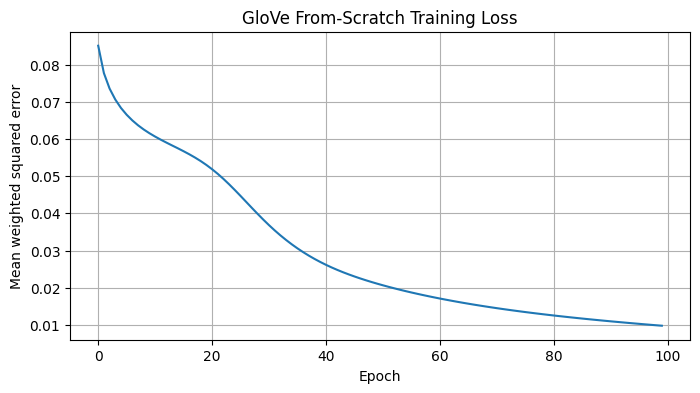

In [6]:
plt.figure(figsize=(8, 4))
plt.plot(glove_model.losses)
plt.xlabel("Epoch")
plt.ylabel("Mean weighted squared error")
plt.title("GloVe From-Scratch Training Loss")
plt.grid(True)
plt.show()

### 4.4 Find words most similar to “king”

Cosine similarity is used to compare the learned word vectors.

In [7]:
custom_similar_words = glove_model.most_similar(
    "king", id_to_word, word_to_id, top_n=10
)
print("Words most similar to 'king' (custom GloVe):")
for word, score in custom_similar_words:
    print(f"{word:15s} {score:.4f}")

Words most similar to 'king' (custom GloVe):
the             0.9740
rules           0.9575
is              0.9378
queen           0.9206
prince          0.9057
princess        0.8858
kingdom         0.8224
books           0.6059
laboratory      0.5980
heat            0.5890


## 5. Experiment 1B — Pretrained GloVe Using Gensim

This section loads the pretrained `glove-wiki-gigaword-100` vectors through Gensim's downloader and queries the nearest words to `king`.

**Note:** The first run downloads the pretrained model (approximately 128 MB), so an internet connection is required. The pretrained model is trained on a much larger external corpus; its results are not directly comparable to the small custom corpus above.

In [8]:
try:
    import gensim.downloader as api

    print("Loading pretrained GloVe vectors. The first run may download the model...")
    pretrained_glove = api.load("glove-wiki-gigaword-100")

    print("\nWords most similar to 'king' (pretrained GloVe):")
    pretrained_similar_words = pretrained_glove.most_similar("king", topn=10)
    for word, score in pretrained_similar_words:
        print(f"{word:15s} {score:.4f}")

except Exception as exc:
    pretrained_glove = None
    print("Could not load the pretrained GloVe model.")
    print("Check your internet connection, Gensim installation, and SciPy compatibility.")
    print("Error:", repr(exc))

Loading pretrained GloVe vectors. The first run may download the model...
[==================================================] 100.0% 128.1/128.1MB downloaded

Words most similar to 'king' (pretrained GloVe):
prince          0.7682
queen           0.7508
son             0.7021
brother         0.6986
monarch         0.6978
throne          0.6920
kingdom         0.6811
father          0.6802
emperor         0.6713
ii              0.6676


### 5.1 Compare custom and pretrained embeddings

The custom model uses only the provided 24-sentence corpus, while the pretrained model uses a much larger Wikipedia + Gigaword corpus. Differences in nearest words are expected.

In [9]:
comparison_rows = [
    {"Model": "Custom GloVe (this corpus)", "Similar words": ", ".join(w for w, _ in custom_similar_words)}
]
if pretrained_glove is not None:
    comparison_rows.append({
        "Model": "Pretrained GloVe (Wiki-Gigaword)",
        "Similar words": ", ".join(w for w, _ in pretrained_similar_words)
    })
display(pd.DataFrame(comparison_rows))

,Model,Similar words
0,Custom GloVe (this corpus),"the, rules, is, queen, prince, princess, kingd..."
1,Pretrained GloVe (Wiki-Gigaword),"prince, queen, son, brother, monarch, throne, ..."


## 6. Experiment 2 — Statistical N-gram Language Model From Scratch

### 6.1 Dataset

The following sentences are taken from the experiment sheet. We lowercase and tokenize them, add start-of-sentence markers, and add an end-of-sentence marker.

In [10]:
lm_sentences = [
    "natural language processing is a branch of artificial intelligence.",
    "natural language processing enables computers to understand human language.",
    "machine learning is a branch of artificial intelligence.",
    "deep learning is a part of machine learning.",
    "language models learn patterns from text data.",
    "a language model predicts the next word in a sentence.",
    "natural language processing uses language models.",
    "artificial intelligence includes machine learning and deep learning."
]

lm_tokenized = [tokenize(sentence) for sentence in lm_sentences]
for sentence in lm_tokenized:
    print(sentence)

['natural', 'language', 'processing', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence']
['natural', 'language', 'processing', 'enables', 'computers', 'to', 'understand', 'human', 'language']
['machine', 'learning', 'is', 'a', 'branch', 'of', 'artificial', 'intelligence']
['deep', 'learning', 'is', 'a', 'part', 'of', 'machine', 'learning']
['language', 'models', 'learn', 'patterns', 'from', 'text', 'data']
['a', 'language', 'model', 'predicts', 'the', 'next', 'word', 'in', 'a', 'sentence']
['natural', 'language', 'processing', 'uses', 'language', 'models']
['artificial', 'intelligence', 'includes', 'machine', 'learning', 'and', 'deep', 'learning']


### 6.2 Build N-gram counts

An N-gram is a sequence of `n` consecutive tokens. For example, a bigram is a two-word sequence and a trigram is a three-word sequence. For an N-gram model, the previous `n-1` words form the context used to estimate the next word.

In [11]:
class NGramLanguageModel:
    def __init__(self, n=2):
        if n < 1:
            raise ValueError("n must be at least 1")
        self.n = n
        self.ngram_counts = Counter()
        self.context_counts = Counter()
        self.vocabulary = set()
        self.total_unigrams = 0

    def fit(self, tokenized_sentences):
        self.ngram_counts.clear()
        self.context_counts.clear()
        self.vocabulary = set()

        for tokens in tokenized_sentences:
            self.vocabulary.update(tokens)
            padded = ["<s>"] * (self.n - 1) + tokens + ["</s>"]
            for i in range(self.n - 1, len(padded)):
                ngram = tuple(padded[i - self.n + 1:i + 1])
                context = ngram[:-1]
                self.ngram_counts[ngram] += 1
                self.context_counts[context] += 1

        self.vocabulary.update(["</s>", "<unk>"])
        self.total_unigrams = sum(
            count for ngram, count in self.ngram_counts.items() if len(ngram) == 1
        )
        return self

    def _context(self, preceding_words):
        if self.n == 1:
            return tuple()
        words = tokenize(preceding_words) if isinstance(preceding_words, str) else list(preceding_words)
        words = [w if w in self.vocabulary else "<unk>" for w in words]
        return tuple((["<s>"] * max(0, self.n - 1 - len(words)) + words)[-(self.n - 1):])

    def predict_next(self, preceding_words, top_k=5, smoothing=1.0):
        context = self._context(preceding_words)
        candidates = sorted(self.vocabulary)
        denominator = self.context_counts[context] + smoothing * len(candidates)

        scored = []
        for word in candidates:
            ngram = context + (word,)
            probability = (self.ngram_counts[ngram] + smoothing) / denominator
            scored.append((word, probability))

        return sorted(scored, key=lambda item: item[1], reverse=True)[:top_k]

    def probability(self, next_word, preceding_words, smoothing=1.0):
        context = self._context(preceding_words)
        word = next_word if next_word in self.vocabulary else "<unk>"
        candidates_count = len(self.vocabulary)
        numerator = self.ngram_counts[context + (word,)] + smoothing
        denominator = self.context_counts[context] + smoothing * candidates_count
        return numerator / denominator

bigram_model = NGramLanguageModel(n=2).fit(lm_tokenized)
trigram_model = NGramLanguageModel(n=3).fit(lm_tokenized)

print("Bigram count examples:")
for ngram, count in bigram_model.ngram_counts.most_common(10):
    print(ngram, ":", count)

print("\nTrigram count examples:")
for ngram, count in trigram_model.ngram_counts.most_common(10):
    print(ngram, ":", count)

Bigram count examples:
('<s>', 'natural') : 3
('natural', 'language') : 3
('language', 'processing') : 3
('is', 'a') : 3
('artificial', 'intelligence') : 3
('machine', 'learning') : 3
('a', 'branch') : 2
('branch', 'of') : 2
('of', 'artificial') : 2
('intelligence', '</s>') : 2

Trigram count examples:
('<s>', '<s>', 'natural') : 3
('<s>', 'natural', 'language') : 3
('natural', 'language', 'processing') : 3
('is', 'a', 'branch') : 2
('a', 'branch', 'of') : 2
('branch', 'of', 'artificial') : 2
('of', 'artificial', 'intelligence') : 2
('artificial', 'intelligence', '</s>') : 2
('learning', 'is', 'a') : 2
('language', 'processing', 'is') : 1


### 6.3 Predict the next word

The model uses **add-one (Laplace) smoothing** so that an unseen N-gram receives a non-zero probability. Try changing the context strings to test other predictions.

In [12]:
test_contexts = [
    "natural language",
    "machine learning",
    "artificial intelligence",
    "a language model"
]

for context in test_contexts:
    print(f"\nContext: {context!r}")
    print("Bigram predictions:")
    for word, probability in bigram_model.predict_next(context, top_k=5):
        print(f"  {word:15s} P={probability:.4f}")

    print("Trigram predictions:")
    for word, probability in trigram_model.predict_next(context, top_k=5):
        print(f"  {word:15s} P={probability:.4f}")


Context: 'natural language'
Bigram predictions:
  processing      P=0.0930
  models          P=0.0698
  </s>            P=0.0465
  model           P=0.0465
  <unk>           P=0.0233
Trigram predictions:
  processing      P=0.1026
  </s>            P=0.0256
  <unk>           P=0.0256
  a               P=0.0256
  and             P=0.0256

Context: 'machine learning'
Bigram predictions:
  </s>            P=0.0732
  is              P=0.0732
  and             P=0.0488
  <unk>           P=0.0244
  a               P=0.0244
Trigram predictions:
  </s>            P=0.0513
  and             P=0.0513
  is              P=0.0513
  <unk>           P=0.0256
  a               P=0.0256

Context: 'artificial intelligence'
Bigram predictions:
  </s>            P=0.0769
  includes        P=0.0513
  <unk>           P=0.0256
  a               P=0.0256
  and             P=0.0256
Trigram predictions:
  </s>            P=0.0769
  includes        P=0.0513
  <unk>           P=0.0256
  a               P=0.0256


### 6.4 Predict one word from a supplied context

Edit `context_to_test` below and rerun the cell. The output lists the top five next-word candidates according to both models.

In [13]:
context_to_test = "machine learning"

print("Context:", context_to_test)
for label, model in [("Bigram", bigram_model), ("Trigram", trigram_model)]:
    print(f"\n{label} model:")
    predictions = model.predict_next(context_to_test, top_k=5)
    for rank, (word, probability) in enumerate(predictions, start=1):
        print(f"{rank}. {word}  (probability={probability:.4f})")

Context: machine learning

Bigram model:
1. </s>  (probability=0.0732)
2. is  (probability=0.0732)
3. and  (probability=0.0488)
4. <unk>  (probability=0.0244)
5. a  (probability=0.0244)

Trigram model:
1. </s>  (probability=0.0513)
2. and  (probability=0.0513)
3. is  (probability=0.0513)
4. <unk>  (probability=0.0256)
5. a  (probability=0.0256)


### 6.5 Compare N-gram probabilities for a candidate next word

In [14]:
context = "machine learning"
candidate = "is"

print(f"P({candidate!r} | {context!r})")
print("Bigram :", round(bigram_model.probability(candidate, context), 6))
print("Trigram:", round(trigram_model.probability(candidate, context), 6))

P('is' | 'machine learning')
Bigram : 0.073171
Trigram: 0.051282


## 7. Results and Observations

Complete this section after running all cells. Use the actual outputs generated in your runtime.

1. The custom GloVe implementation constructs a word co-occurrence matrix and learns embeddings by minimizing the weighted GloVe objective.
2. The nearest words to `king` from the custom model depend strongly on the small supplied corpus, context-window size, embedding dimension, and training settings.
3. The pretrained Gensim GloVe vectors are trained on a much larger corpus and generally capture broader semantic relationships.
4. The N-gram model estimates the next-word probability from the preceding `n-1` words. The bigram model uses one preceding word; the trigram model uses two.
5. Add-one smoothing prevents zero probabilities for unseen N-grams, although it can make predictions less sharply concentrated.

**Result:** The GloVe algorithm (from scratch and using pretrained Gensim vectors) and a statistical N-gram language model have been implemented. The notebook prints the words most similar to `king` and predicts likely next words for user-provided contexts.

## 8. References

- Pennington, J., Socher, R., and Manning, C. D. (2014). *GloVe: Global Vectors for Word Representation*. Proceedings of EMNLP.
- Gensim documentation: https://radimrehurek.com/gensim/
- Gensim pretrained vector downloader: https://github.com/piskvorky/gensim-data

---

**End of Experiment 6**